Generating Synthetic Data...
Data Generated Successfully! Shape: (36, 1)


,Demand
Date,
2021-01-31,61.246218
2021-02-28,76.504620
2021-03-31,100.718426
2021-04-30,124.447510
2021-05-31,145.368286



--- EDA: Trend & Seasonality ---


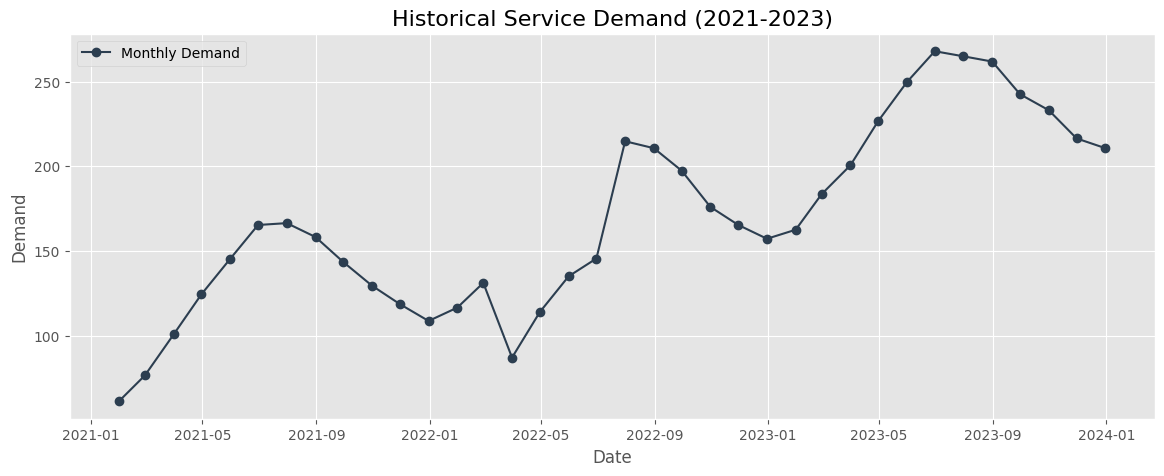

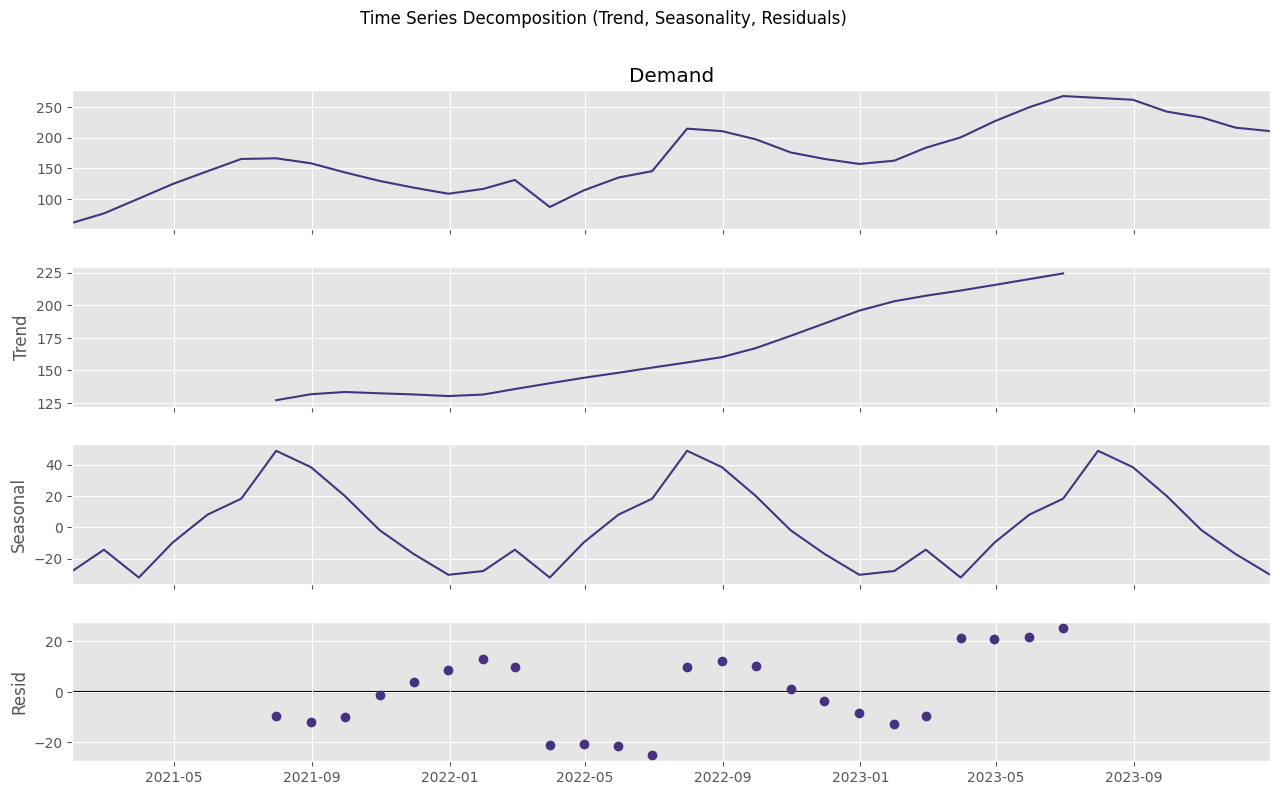


--- Baseline Model (Moving Average) ---

--- Training Advanced Models ---

--- Model Evaluation ---
Baseline (Moving Avg) -> MAE: 20.05, RMSE: 22.86, MAPE: 8.79%
SARIMA -> MAE: 2.96, RMSE: 3.81, MAPE: 1.25%
Random Forest -> MAE: 20.03, RMSE: 24.05, MAPE: 8.95%


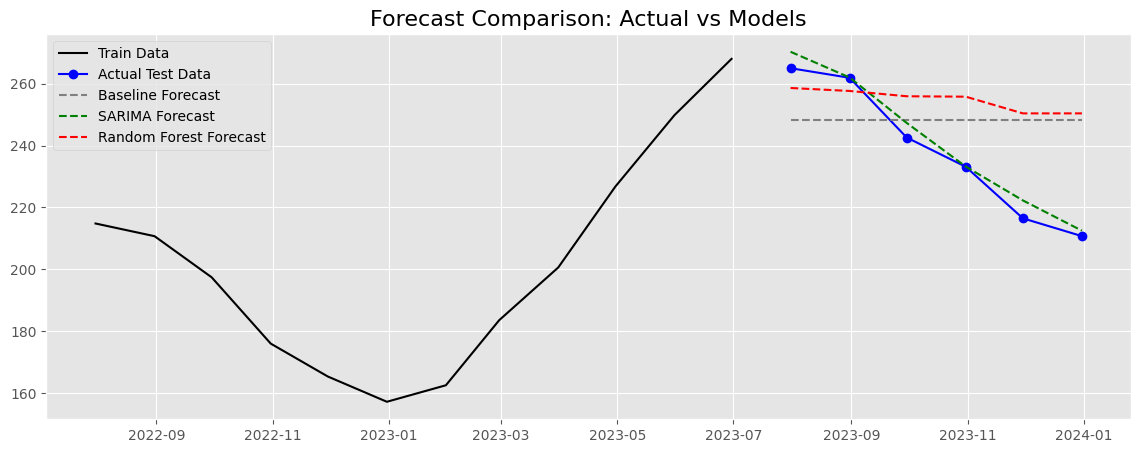


--- Saving Models ---
Models and Data saved successfully! Download 'rf_model.pkl' and 'historical_data.csv' from the left sidebar to use in Streamlit.


In [1]:
# ==========================================
# CELL 1: Install Libraries & Imports
# ==========================================
!pip install statsmodels joblib -q

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import joblib
import warnings
warnings.filterwarnings('ignore')

# Plot styling
plt.style.use('ggplot')
sns.set_palette("viridis")

# ==========================================
# CELL 2: Synthetic Data Generation
# ==========================================
print("Generating Synthetic Data...")
# 3 saal ka daily data (2021 to 2023)
dates = pd.date_range(start='2021-01-01', end='2023-12-31', freq='D')
np.random.seed(42)

# Trend: Demand slowly increasing
trend = np.linspace(100, 250, len(dates))

# Seasonality: Tech services ki demand year-end (Dec) aur Q1 mein high hoti hai
# Sine wave banate hain jo December mein peak kare
seasonality = 40 * np.sin(2 * np.pi * (dates.dayofyear - 90) / 365.25)

# Noise: Random variations
noise = np.random.normal(0, 15, len(dates))

# Ek sudden dip daal dete hain (jaise koi economic slowdown ya pandemic ho gaya)
# Yeh hint ke liye hai: "historical trends may not always predict future"
dip = np.where((dates >= '2022-03-01') & (dates <= '2022-06-30'), -60, 0)

# Final Demand calculation
demand = trend + seasonality + noise + dip
demand = np.maximum(demand, 10) # Demand negative nahi ho sakti

# DataFrame banayein
df = pd.DataFrame({'Date': dates, 'Demand': demand})
df.set_index('Date', inplace=True)

# Monthly resampling (Forecasting ke liye monthly data better hota hai)
monthly_df = df.resample('M').mean()

print("Data Generated Successfully! Shape:", monthly_df.shape)
display(monthly_df.head())

# ==========================================
# CELL 3: Exploratory Data Analysis (EDA)
# ==========================================
print("\n--- EDA: Trend & Seasonality ---")
plt.figure(figsize=(14, 5))
plt.plot(monthly_df.index, monthly_df['Demand'], marker='o', color='#2c3e50', label='Monthly Demand')
plt.title('Historical Service Demand (2021-2023)', fontsize=16)
plt.xlabel('Date')
plt.ylabel('Demand')
plt.legend()
plt.grid(True)
plt.show()

# Seasonal Decomposition
decomposition = seasonal_decompose(monthly_df['Demand'], model='additive', period=12)
fig = decomposition.plot()
fig.set_size_inches(14, 8)
plt.suptitle('Time Series Decomposition (Trend, Seasonality, Residuals)', y=1.02)
plt.show()

# ==========================================
# CELL 4: Train-Test Split & Baseline Model
# ==========================================
print("\n--- Baseline Model (Moving Average) ---")
# Last 6 months test ke liye rakhte hain
train = monthly_df.iloc[:-6]
test = monthly_df.iloc[-6:]

# Baseline: 3-month Moving Average
baseline_pred = train['Demand'].rolling(window=3).mean().iloc[-1]
baseline_forecast = [baseline_pred] * len(test)

# ==========================================
# CELL 5: Advanced Models (SARIMA & Random Forest)
# ==========================================
print("\n--- Training Advanced Models ---")

# 1. SARIMA Model
sarima_model = SARIMAX(train['Demand'], order=(1, 1, 1), seasonal_order=(1, 1, 1, 12))
sarima_result = sarima_model.fit(disp=False)
sarima_forecast = sarima_result.forecast(steps=len(test))

# 2. Random Forest Model (Feature Engineering)
def create_features(data):
    df_feat = data.copy()
    df_feat['Month'] = df_feat.index.month
    df_feat['Quarter'] = df_feat.index.quarter
    df_feat['Lag_1'] = df_feat['Demand'].shift(1)
    df_feat['Lag_2'] = df_feat['Demand'].shift(2)
    df_feat['Rolling_Mean_3'] = df_feat['Demand'].rolling(window=3).mean()
    return df_feat.dropna()

train_feat = create_features(train)
X_train = train_feat.drop('Demand', axis=1)
y_train = train_feat['Demand']

rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# RF Prediction (Iterative approach for future)
rf_forecast = []
last_data = train.copy()
for i in range(len(test)):
    # Create features for next step
    temp_df = create_features(last_data)
    last_row = temp_df.iloc[-1:].drop('Demand', axis=1)

    # Predict
    pred = rf_model.predict(last_row)[0]
    rf_forecast.append(pred)

    # Append prediction to data for next iteration
    next_date = last_data.index[-1] + pd.DateOffset(months=1)
    last_data = pd.concat([last_data, pd.DataFrame({'Demand': [pred]}, index=[next_date])])

# ==========================================
# CELL 6: Model Evaluation & Comparison
# ==========================================
print("\n--- Model Evaluation ---")
def calculate_metrics(actual, predicted, model_name):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    mape = np.mean(np.abs((actual - predicted) / actual)) * 100
    print(f"{model_name} -> MAE: {mae:.2f}, RMSE: {rmse:.2f}, MAPE: {mape:.2f}%")
    return mae, rmse, mape

calculate_metrics(test['Demand'], baseline_forecast, "Baseline (Moving Avg)")
calculate_metrics(test['Demand'], sarima_forecast, "SARIMA")
calculate_metrics(test['Demand'], rf_forecast, "Random Forest")

# Plot Comparison
plt.figure(figsize=(14, 5))
plt.plot(train.index[-12:], train['Demand'].iloc[-12:], label='Train Data', color='black')
plt.plot(test.index, test['Demand'], label='Actual Test Data', color='blue', marker='o')
plt.plot(test.index, baseline_forecast, label='Baseline Forecast', linestyle='--', color='gray')
plt.plot(test.index, sarima_forecast, label='SARIMA Forecast', linestyle='--', color='green')
plt.plot(test.index, rf_forecast, label='Random Forest Forecast', linestyle='--', color='red')
plt.title('Forecast Comparison: Actual vs Models', fontsize=16)
plt.legend()
plt.grid(True)
plt.show()

# ==========================================
# CELL 7: Save Models for Streamlit Dashboard
# ==========================================
print("\n--- Saving Models ---")
# Save the Random Forest model and the last known data for Streamlit
joblib.dump(rf_model, 'rf_model.pkl')
monthly_df.to_csv('historical_data.csv')

print("Models and Data saved successfully! Download 'rf_model.pkl' and 'historical_data.csv' from the left sidebar to use in Streamlit.")

In [2]:
from google.colab import files

# Model file download karne ke liye
files.download('rf_model.pkl')

# CSV file download karne ke liye
files.download('historical_data.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>